# Introduction to SymPy

**Seong Cho** · ACME Python Essentials, Lab 10

**Lab objective:** introduce SymPy, Python's library for symbolic mathematics (algebra, differentiation, integration, and more), and emphasize how to use symbolic algebra for numerical computing.

<sub>Lab specification from the *Python Essentials* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

`sy.init_printing()` renders expressions with LaTeX in the notebook (see *Pretty Printing* under Additional Material); `print()` still shows the plain-text form.

In [1]:
import sympy as sy
import numpy as np
import matplotlib.pyplot as plt

sy.init_printing(use_latex="mathjax")    # LaTeX output rendered by the notebook (no PNG images).

## Symbolic Variables and Expressions

A *symbolic variable* represents a mathematical symbol such as $x$ or $\theta$, not a number or another kind of data, and operating on symbolic variables produces an *expression*. If `Y` refers to the mathematical variable $y$, then `3*Y` is the expression $3y$, without ever assigning a value to `Y`. SymPy is typically imported as `sy`, and symbolic variables are usually defined with `sy.symbols()`.

In [2]:
x0 = sy.symbols('x0')                       # Define a single variable.
x2, x3 = sy.symbols('x2, x3')               # Separate symbols by commas,
m, a = sy.symbols('mass acceleration')      # by spaces,
x, y, z = sy.symbols('x:z')                 # or by colons.
x4, x5, x6 = sy.symbols('x4:7')

expr = x**2 + x*y + 3*x*y + 4*y**3          # Combine symbolic variables to form expressions.
force = m * a
print(expr, force, sep='\n')

x**2 + 4*x*y + 4*y**3
acceleration*mass


SymPy has its own version of each standard mathematical function and predefined special numbers. Most names match NumPy, but some constants differ:

| | $\sin(x)$ | $\arcsin(x)$ | $\sinh(x)$ | $e^x$ | $\log(x)$ | $\sqrt{x}$ |
|---|---|---|---|---|---|---|
| **Functions** | `sy.sin()` | `sy.asin()` | `sy.sinh()` | `sy.exp()` | `sy.log()` | `sy.sqrt()` |

| | $\pi$ | $e$ | $i = \sqrt{-1}$ | $\infty$ |
|---|---|---|---|---|
| **Constants** | `sy.pi` | `sy.E` | `sy.I` | `sy.oo` |

Other trigonometric functions like $\cos(x)$ follow the same conventions. For a more complete list, see http://docs.sympy.org/latest/modules/functions/index.html.

> **Achtung!** Always use SymPy functions and constants when creating expressions instead of using NumPy's functions and constants. Later we will show how to make NumPy and SymPy cooperate.

In [3]:
x = sy.symbols('x')
try:
    np.exp(x)                               # Try to use NumPy to represent e**x.
except Exception as e:
    print(type(e).__name__ + ":", e)
sy.exp(x)                                   # Use SymPy's version instead.

TypeError: loop of ufunc does not support argument 0 of type Symbol which has no callable exp method


 x
ℯ 

> **Note.** SymPy defines its own numeric types for integers, floats, and rational numbers. For example, the `sy.Rational` class is similar to the standard library's `fractions.Fraction` class, and should be used to represent fractions in SymPy expressions. Always be aware of which numeric types are being used in an expression. Using rationals and integers where possible is important in simplifying expressions.

In [4]:
(2/3) * sy.sin(x), sy.Rational(2, 3) * sy.sin(x)       # 2/3 is a float; the Rational stays symbolic.

⎛                          2⋅sin(x)⎞
⎜0.666666666666667⋅sin(x), ────────⎟
⎝                             3    ⎠

## Problem 1: A symbolic expression

> **Problem 1.** Write a function that returns the expression $\frac{2}{5}e^{x^2-y}\cosh(x+y) + \frac{3}{7}\log(xy + 1)$ symbolically. Make sure that the fractions remain symbolic.

In [5]:
def prob1():
    """Return an expression for

        (2/5)e^(x^2 - y)cosh(x+y) + (3/7)log(xy + 1).

    Make sure that the fractions remain symbolic.
    """
    x, y = sy.symbols('x, y')
    return sy.Rational(2,5) * sy.exp(x**2 - y) * sy.cosh(x + y) + \
           sy.Rational(3,7) * sy.log(x*y + 1)

prob1()

    2                                 
   x  - y                             
2⋅ℯ      ⋅cosh(x + y)   3⋅log(x⋅y + 1)
───────────────────── + ──────────────
          5                   7       

## Sums and Products

`sy.summation()` and `sy.product()` build sums and products. Each takes an expression for one term, then a tuple with the indexing variable and its bounds. For example, $\sum_{i=1}^{4} x + iy$ and $\prod_{i=0}^{5} x + iy$:

In [6]:
x, y, i = sy.symbols('x y i')
sy.summation(x + i*y, (i, 1, 4)), sy.product(x + i*y, (i, 0, 5))      # Sum over i=1,...,4; multiply over i=0,...,5.

(4⋅x + 10⋅y, x⋅(x + y)⋅(x + 2⋅y)⋅(x + 3⋅y)⋅(x + 4⋅y)⋅(x + 5⋅y))

## Simplifying Expressions

Those results were simplified automatically. More complicated expressions can be simplified with:

| Function | Description |
|---|---|
| `sy.cancel()` | Cancel common factors in the numerator and denominator. |
| `sy.expand()` | Expand a factored expression. |
| `sy.factor()` | Factor an expanded expression. |
| `sy.radsimp()` | Rationalize the denominator of an expression. |
| `sy.simplify()` | Simplify an expression. |
| `sy.trigsimp()` | Simplify only the trigonometric parts of the expression. |

The generic `sy.simplify()` tries every way it knows, which is often computationally expensive; the more specific simplifiers are cheaper when they apply. See http://docs.sympy.org/latest/tutorial/simplification.html for more examples.

In [7]:
x = sy.symbols('x')
expr = (x**2 + 2*x + 1) / ((x+1)*((sy.sin(x)/sy.cos(x))**2 + 1))
expr, sy.simplify(expr)

⎛     2                                ⎞
⎜    x  + 2⋅x + 1                  2   ⎟
⎜─────────────────────, (x + 1)⋅cos (x)⎟
⎜        ⎛   2       ⎞                 ⎟
⎜        ⎜sin (x)    ⎟                 ⎟
⎜(x + 1)⋅⎜─────── + 1⎟                 ⎟
⎜        ⎜   2       ⎟                 ⎟
⎝        ⎝cos (x)    ⎠                 ⎠

In [8]:
expr = sy.product(x + i*y, (i, 0, 3))
expr_long = sy.expand(expr)                 # Expand the product terms.
expr_long /= (x + 3*y)
expr_short = sy.cancel(expr_long)           # Cancel out the denominator.
for e in (expr, expr_long, expr_short, sy.factor(expr_short)):   # Factor the result.
    print(e)
sy.trigsimp(2*sy.sin(x)*sy.cos(x))          # Simplify the trigonometric parts of an expression.

x*(x + y)*(x + 2*y)*(x + 3*y)
(x**4 + 6*x**3*y + 11*x**2*y**2 + 6*x*y**3)/(x + 3*y)
x**3 + 3*x**2*y + 2*x*y**2
x*(x + y)*(x + 2*y)


sin(2⋅x)

> **Achtung!**
> 1. Simplifications return new expressions; they do not modify existing expressions in place.
> 2. The `==` operator compares two expressions for exact structural equality, not algebraic equivalence. Simplify or expand expressions before comparing them with `==`.
> 3. Expressions containing floats may not simplify as expected. Always use integers and SymPy rationals in expressions when appropriate.

In [9]:
expr = 2*sy.sin(x)*sy.cos(x)
sy.trigsimp(expr)
print(expr)                                             # The original expression is unchanged.
print(2*sy.sin(x)*sy.cos(x) == sy.sin(2*x))             # The two expression structures differ.
print(sy.factor(x**2.0 - 1))                            # Factorization fails due to the 2.0.

2*sin(x)*cos(x)
False
x**2.0 - 1


## Problem 2: Simplifying a product of sums

> **Problem 2.** Write a function that computes and simplifies the following expression.
>
> $$\prod_{i=1}^{5} \sum_{j=i}^{5} j(\sin(x) + \cos(x))$$

In [10]:
def prob2():
    """Compute and simplify the following expression.

        product_(i=1 to 5)[ sum_(j=i to 5)[j(sin(x) + cos(x))] ]
    """
    x, i, j = sy.symbols('x, i, j')
    expr = sy.product(sy.summation(j*(sy.sin(x) + sy.cos(x)), (j, i, 5)), (i, 1, 5))
    return sy.simplify(expr)

prob2()

             5⎛    π⎞
453600⋅√2⋅sin ⎜x + ─⎟
              ⎝    4⎠

As a check, the inner sums are $15, 14, 12, 9, 5$ times $(\sin x + \cos x)$, so the product is $113400(\sin x + \cos x)^5$, and $\sin x + \cos x = \sqrt{2}\sin(x + \pi/4)$ turns that into the form above:

In [11]:
sy.simplify(prob2() - 113400*(sy.sin(x) + sy.cos(x))**5) == 0

True

## Evaluating Expressions

Every expression has a `subs()` method that substitutes one variable for another; the result is usually still symbolic, even when a number is substituted. `evalf()` evaluates the expression numerically once every symbol has a value. Both accept a dictionary to reassign several symbols at once.

In [12]:
x, y = sy.symbols('x y')
expr = sy.expand((x + y)**3)
new_expr = expr.subs({x:sy.pi, y:1})                # Replace x with pi and y with 1.
print(expr, expr.subs(y, 2*x), new_expr, sep='\n')  # ...and y with the expression 2x.
new_expr.evalf(), expr.evalf(subs={x:1, y:2})       # Evaluate numerically.

x**3 + 3*x**2*y + 3*x*y**2 + y**3
27*x**3
1 + 3*pi + 3*pi**2 + pi**3


(71.0398678443373, 27.0)

To evaluate an expression at many points, `sy.lambdify()` turns it into a reusable numerical function. It takes a symbolic variable (or list of variables) and an expression, and returns a callable.

In [13]:
f = sy.lambdify(x, sy.sin(x)**2)
print(f(0), f(np.pi/2), f(np.pi), sep='   ')
f = sy.lambdify((x,y), sy.sin(x)**2 + sy.cos(y)**2)     # A function of several variables.
print(f(0,1), f(1,0), f(np.pi, np.pi), sep='   ')

0.0   1.0   1.4997597826618576e-32
0.2919265817264289   1.708073418273571   1.0


By default, `sy.lambdify()` uses the `math` module, so `sy.sin()` becomes `math.sin()`. Passing `"numpy"` as an extra argument converts symbolic functions to their NumPy equivalents instead, so the resulting function acts element-wise on NumPy arrays, not just on single data points.

In [14]:
f = sy.lambdify(x, 2*sy.sin(2*x), "numpy")
f(np.linspace(0, 2*np.pi, 9))                           # Evaluate f() at many points.

array([ 0.00000000e+00,  2.00000000e+00,  2.44929360e-16, -2.00000000e+00,
       -4.89858720e-16,  2.00000000e+00,  7.34788079e-16, -2.00000000e+00,
       -9.79717439e-16])

> **Note.** It is almost always computationally cheaper to lambdify a function than to use substitutions. According to the SymPy documentation, using `sy.lambdify()` to do numerical evaluations "takes on the order of hundreds of nanoseconds, roughly two orders of magnitude faster than the `subs()` method."

In the spec's experiment on 10,000 random points, `subs()`/`evalf()` took 5.36 s, the lambdified function 7.75 ms ("about 1000 times faster than `evalf()`"), and the NumPy-lambdified function, applied to the whole array at once, 282 µs ("about 10 times faster than regular lambdify"). The same experiment here (timings vary by machine):

In [15]:
x = sy.symbols('x')
expr = sy.tanh(x)
points = np.random.random(10000)
%time _ = [expr.subs(x, pt).evalf() for pt in points]
f = sy.lambdify(x, expr)
%time _ = [f(pt) for pt in points]
f = sy.lambdify(x, expr, "numpy")
%time _ = f(points)

CPU times: user 577 ms, sys: 4.65 ms, total: 582 ms
Wall time: 582 ms
CPU times: user 3.34 ms, sys: 44 μs, total: 3.38 ms
Wall time: 3.4 ms
CPU times: user 145 μs, sys: 50 μs, total: 195 μs
Wall time: 207 μs


## Problem 3: Maclaurin series of $e^{-y^2}$

> **Problem 3.** The Maclaurin series up to order $N$ for $e^x$ is defined as follows.
>
> $$e^x \approx \sum_{n=0}^{N} \frac{x^n}{n!} \tag{9.1}$$
>
> Write a function that accepts an integer $N$. Define an expression for (9.1), then substitute in $-y^2$ for $x$ to get a truncated Maclaurin series of $e^{-y^2}$. Lambdify the resulting expression and plot the series on the domain $y \in [-2, 2]$. Plot $e^{-y^2}$ over the same domain for comparison.
> (Hint: use `sy.factorial()` to compute the factorial.)
>
> Call your function with increasing values of $N$ to check that the series converges correctly.

In [16]:
def prob3(N):
    """Define an expression for the Maclaurin series of e^x up to order N.
    Substitute in -y^2 for x to get a truncated Maclaurin series of e^(-y^2).
    Lambdify the resulting expression and plot the series on the domain
    y in [-2,2]. Plot e^(-y^2) over the same domain for comparison.
    """
    x, y, n = sy.symbols('x, y, n')
    expr = sy.summation(x**n/sy.factorial(n), (n, 0, N))
    f = sy.lambdify(y, expr.subs(x, -y**2), "numpy")
    domain = np.linspace(-2, 2, 100)
    plt.ion()
    plt.plot(domain, np.exp(-1*domain**2), label="original function")
    plt.plot(domain, f(domain), label="Maclaurin series")
    plt.legend()
    plt.show()

With increasing $N$ the series matches $e^{-y^2}$ on more of the domain (one plot each for $N = 2, 6, 12$):

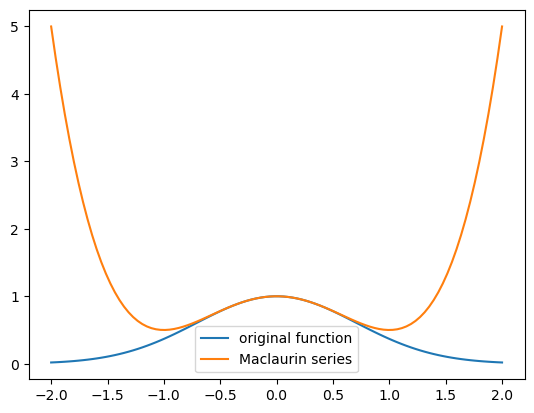

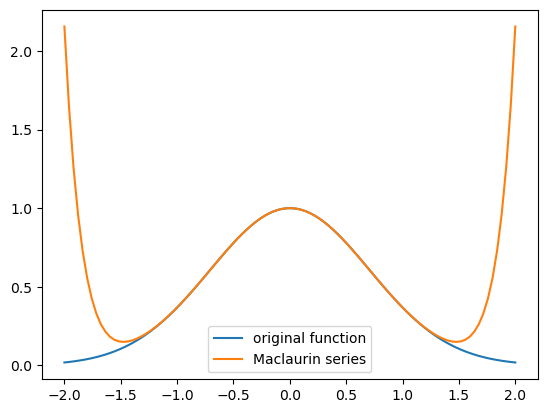

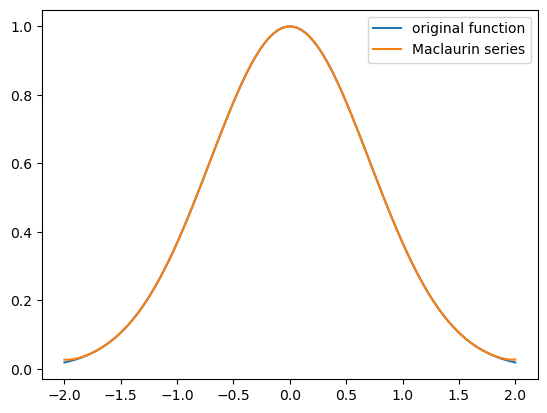

In [17]:
for N in (2, 6, 12):
    prob3(N)

## Solving Symbolic Equations

An expression by itself is not an equation, but `sy.solve()` sets an expression equal to zero and solves for a given variable. The result is a list of solutions, which can be expressions involving other variables.

In [18]:
x, y = sy.symbols('x y')
sy.solve(x**2 - 2*x + 1, x), sy.solve(x**2 - 1, x), sy.solve(x/(y-x) + (x-y)/y, x)

⎛              ⎡y⋅(3 - √5)  y⋅(√5 + 3)⎤⎞
⎜[1], [-1, 1], ⎢──────────, ──────────⎥⎟
⎝              ⎣    2           2     ⎦⎠

## Problem 4: Rose curve

> **Problem 4.** The following equation represents a rose curve in cartesian coordinates.
>
> $$0 = 1 - \frac{(x^2 + y^2)^{7/2} + 18x^5y - 60x^3y^3 + 18xy^5}{(x^2 + y^2)^3} \tag{9.2}$$
>
> The curve is not the image of a single function (such a function would fail the vertical line test), so the best way to plot it is to convert (9.2) to a pair of parametric equations that depend on the angle parameter $\theta$.
>
> Construct an expression for the nonzero side of (9.2) and convert it to polar coordinates with the substitutions $x = r\cos(\theta)$ and $y = r\sin(\theta)$. Simplify the result, then solve it for $r$. There are two solutions due to the presence of an $r^2$ term; pick one and lambdify it to get a function $r(\theta)$. Use this function to plot $x(\theta) = r(\theta)\cos(\theta)$ against $y(\theta) = r(\theta)\sin(\theta)$ for $\theta \in [0, 2\pi]$.
> (Hint: use `sy.Rational()` for the fractional exponent.)

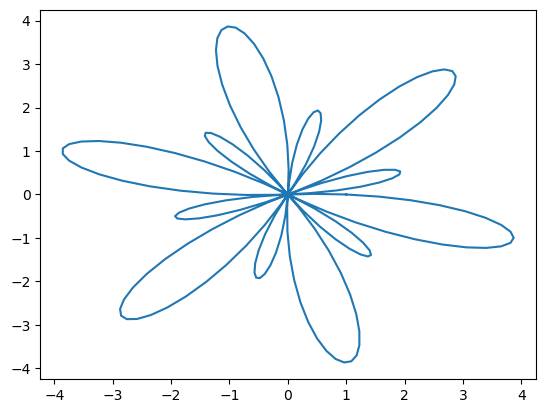

In [19]:
def prob4():
    """The following equation represents a rose curve in cartesian coordinates.

    0 = 1 - [(x^2 + y^2)^(7/2) + 18x^5 y - 60x^3 y^3 + 18x y^5] / (x^2 + y^2)^3

    Construct an expression for the nonzero side of the equation and convert
    it to polar coordinates. Simplify the result, then solve it for r.
    Lambdify a solution and use it to plot x against y for theta in [0, 2pi].
    """
    theta = np.linspace(0, 2*np.pi, 200)
    x, y, r, th = sy.symbols("x, y, r, th")
    expr = 1 - ((x**2 + y**2)**sy.Rational(7,2) + 18*x**5*y \
            - 60*x**3*y**3 + 18*x*y**5)/(x**2 + y**2)**3
    expr = expr.subs({x:r*sy.cos(th), y:r*sy.sin(th)})
    expr = sy.simplify(expr)
    solutions = sy.solve(expr, r)
    r_f = sy.lambdify(th, solutions[0], "numpy")
    plt.ion()
    plt.plot(r_f(theta)*np.cos(theta), r_f(theta)*np.sin(theta))
    plt.show()

prob4()

## Linear Algebra

SymPy solves a linear system $A\mathbf{x} = \mathbf{b}$ differently from NumPy and SciPy: define the augmented matrix $M = [A \mid \mathbf{b}]$ with `sy.Matrix()` (same syntax as 2-D NumPy arrays) and call `sy.solve_linear_system()` on it. For example, the system

$$\begin{aligned} x + y + z &= 5 \\ 2x + 4y + 3z &= 2 \\ 5x + 10y + 2z &= 4 \end{aligned}$$

In [20]:
x, y, z = sy.symbols('x y z')
M = sy.Matrix([ [1,  1, 1, 5],                  # Define the augmented matrix M = [A|b].
                [2,  4, 3, 2],
                [5, 10, 2, 4] ])
sy.solve_linear_system(M, x, y, z)              # Provide the symbolic variables to solve for.

⎧   98     -45          ⎫
⎨x: ──, y: ────, z: 2/11⎬
⎩   11      11          ⎭

SymPy matrices support addition `+`, subtraction `-`, and multiplication `@`, plus many methods (see http://docs.sympy.org/latest/modules/matrices/matrices.html):

| Method | Returns |
|---|---|
| `det()` | The determinant. |
| `eigenvals()` | The eigenvalues and their multiplicities. |
| `eigenvects()` | The eigenvectors and their corresponding eigenvalues. |
| `inv()` | The matrix inverse. |
| `is_nilpotent()` | True if the matrix is nilpotent. |
| `norm()` | The Frobenius, $\infty$, 1, or 2 norm. |
| `nullspace()` | The nullspace as a list of vectors. |
| `rref()` | The reduced row-echelon form. |
| `singular_values()` | The singular values. |

> **Achtung!** The `*` operator performs matrix multiplication on SymPy matrices. To perform element-wise multiplication, use the `multiply_elementwise()` method instead.

In [21]:
A = sy.Matrix([[1, 2], [3, 4]])
A * A, A.multiply_elementwise(A)

⎛⎡7   10⎤  ⎡1  4 ⎤⎞
⎜⎢      ⎥, ⎢     ⎥⎟
⎝⎣15  22⎦  ⎣9  16⎦⎠

## Problem 5: Symbolic eigenvalues and eigenvectors

> **Problem 5.** Find the eigenvalues of the following matrix by solving for $\lambda$ in the characteristic equation $\det(A - \lambda I) = 0$.
>
> $$A = \begin{bmatrix} x-y & x & 0 \\ x & x-y & x \\ 0 & x & x-y \end{bmatrix}$$
>
> Also compute the eigenvectors by solving the linear system $A - \lambda I = 0$ for each eigenvalue $\lambda$. Return a dictionary mapping the eigenvalues to their eigenvectors.
> (Hint: the `nullspace()` method may be useful.)
>
> Check that $A\mathbf{v} = \lambda\mathbf{v}$ for each eigenvalue-eigenvector pair $(\lambda, \mathbf{v})$. Compare your results to the `eigenvals()` and `eigenvects()` methods for SymPy matrices.

In [22]:
def prob5():
    """Calculate the eigenvalues and eigenvectors of the following matrix.

            [x-y,   x,   0]
        A = [  x, x-y,   x]
            [  0,   x, x-y]

    Returns:
        (dict): a dictionary mapping eigenvalues (as expressions) to the
            corresponding eigenvectors (as SymPy matrices).
    """
    x, y, l = sy.symbols('x, y, l')
    A = sy.Matrix([[x-y, x, 0],
                   [x, x-y, x],
                   [0, x, x-y]])
    char_poly = sy.det(A - l*sy.eye(3))
    eig_vals = sy.solve(char_poly, l)
    eig_dict = {}
    for v in eig_vals:
        eig_dict[v] = (A - v*sy.eye(3)).nullspace()
    return eig_dict

eig_dict = prob5()
eig_dict

⎧       ⎡⎡-1⎤⎤                ⎡⎡1 ⎤⎤                 ⎡⎡ 1 ⎤⎤⎫
⎪       ⎢⎢  ⎥⎥                ⎢⎢  ⎥⎥                 ⎢⎢   ⎥⎥⎪
⎨x - y: ⎢⎢0 ⎥⎥, x + √2⋅x - y: ⎢⎢√2⎥⎥, -√2⋅x + x - y: ⎢⎢-√2⎥⎥⎬
⎪       ⎢⎢  ⎥⎥                ⎢⎢  ⎥⎥                 ⎢⎢   ⎥⎥⎪
⎩       ⎣⎣1 ⎦⎦                ⎣⎣1 ⎦⎦                 ⎣⎣ 1 ⎦⎦⎭

Check $A\mathbf{v} = \lambda\mathbf{v}$ for every pair, then compare with SymPy's built-in methods:

In [23]:
x, y = sy.symbols('x, y')
A = sy.Matrix([[x-y, x, 0],
               [x, x-y, x],
               [0, x, x-y]])
print(all(sy.simplify(A @ v - lam * v) == sy.zeros(3, 1) for lam, vecs in eig_dict.items() for v in vecs))
A.eigenvals(), A.eigenvects()

True


⎛                                               ⎡                    ⎛         ↪
⎜                                               ⎢⎛          ⎡⎡-1⎤⎤⎞  ⎜         ↪
⎜                                               ⎢⎜          ⎢⎢  ⎥⎥⎟  ⎜         ↪
⎜{x - y: 1, x + √2⋅x - y: 1, -√2⋅x + x - y: 1}, ⎢⎜x - y, 1, ⎢⎢0 ⎥⎥⎟, ⎜x + √2⋅x ↪
⎜                                               ⎢⎜          ⎢⎢  ⎥⎥⎟  ⎜         ↪
⎜                                               ⎢⎝          ⎣⎣1 ⎦⎦⎠  ⎜         ↪
⎝                                               ⎣                    ⎝         ↪

↪          ⎡⎡          1          ⎤⎤⎞  ⎛                  ⎡⎡          1        ↪
↪          ⎢⎢                     ⎥⎥⎟  ⎜                  ⎢⎢                   ↪
↪          ⎢⎢-x + y   x + √2⋅x - y⎥⎥⎟  ⎜                  ⎢⎢-x + y   -√2⋅x + x ↪
↪  - y, 1, ⎢⎢────── + ────────────⎥⎥⎟, ⎜-√2⋅x + x - y, 1, ⎢⎢────── + ───────── ↪
↪          ⎢⎢  x           x      ⎥⎥⎟  ⎜                  ⎢⎢  x            x   ↪
↪          ⎢⎢              

## Calculus

SymPy also does derivatives, integrals, and limits. Like other symbolic operations these can be slow, but they give exact solutions whenever solutions exist.

### Differentiation

`sy.Derivative()` creates an unevaluated derivative, like writing $\frac{d}{dx}$ in front of an expression; its `doit()` method performs the differentiation. `sy.diff()` differentiates in one step. Both take an expression, then the variable or variables to differentiate with respect to.

In [24]:
x, y = sy.symbols('x y')
f = sy.sin(y)*sy.cos(x)**2
df = sy.Derivative(f, x)        # An expression for the derivative of f with respect to x.
print(df)
df.doit(), sy.diff(f, x), sy.diff(f, x, y, x)   # The last is d/dx, then d/dy, then d/dx again (and could be simplified).

Derivative(sin(y)*cos(x)**2, x)


⎛                                                    ⎛   2         2   ⎞       ⎞
⎝-2⋅sin(x)⋅sin(y)⋅cos(x), -2⋅sin(x)⋅sin(y)⋅cos(x), 2⋅⎝sin (x) - cos (x)⎠⋅cos(y)⎠

## Problem 6: Critical points

> **Problem 6.** Let $f: \mathbb{R} \to \mathbb{R}$ be a smooth function. A *critical point* of $f$ is a number $x_0 \in \mathbb{R}$ satisfying $f'(x_0) = 0$. The *second derivative test* states that a critical point $x_0$ is a local minimum of $f$ if $f''(x_0) > 0$, or a local maximum of $f$ if $f''(x_0) < 0$ (if $f''(x_0) = 0$, the test is inconclusive).
>
> Now consider the following polynomial.
>
> $$p(x) = 2x^6 - 51x^4 + 48x^3 + 312x^2 - 576x - 100$$
>
> Use SymPy to find all critical points of $p$ and classify each as a local minimum or a local maximum. Plot $p(x)$ over $x \in [-5, 5]$ and mark each of the minima in one color and the maxima in another color. Return the collections of local minima and local maxima as sets.

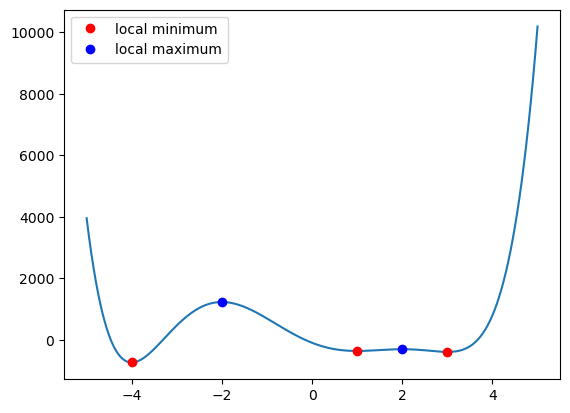

({-4, 1, 3}, {-2, 2})

In [25]:
def prob6():
    """Consider the following polynomial.

        p(x) = 2*x^6 - 51*x^4 + 48*x^3 + 312*x^2 - 576*x - 100

    Plot the polynomial and its critical points. Determine which points are
    maxima and which are minima.

    Returns:
        (set): the local minima.
        (set): the local maxima.
    """
    domain = np.linspace(-5, 5, 200)
    x = sy.symbols('x')
    poly = 2*x**6 - 51*x**4 + 48*x**3 + 312*x**2 - 576*x - 100
    f = sy.lambdify(x, poly)
    _1deriv = sy.diff(poly, x)
    critical_pts = sy.solve(_1deriv, x)
    _2deriv = sy.diff(_1deriv, x)
    f_2deriv = sy.lambdify(x, _2deriv)
    loc_min = []
    loc_max = []
    for x0 in critical_pts:
        if f_2deriv(x0) > 0:
            loc_min.append(x0)
        if f_2deriv(x0) < 0:
            loc_max.append(x0)

    plt.ion()
    plt.plot(domain, f(domain))
    plt.plot(loc_min, f(np.array(loc_min)), 'ro', label="local minimum")
    plt.plot(loc_max, f(np.array(loc_max)), 'bo', label="local maximum")
    plt.legend()
    plt.show()

    return set(loc_min), set(loc_max)

prob6()

### The Jacobian

The *Jacobian matrix* of a multivariable function $f: \mathbb{R}^n \to \mathbb{R}^m$ at a point $\mathbf{x}_0 \in \mathbb{R}^n$ is the $m \times n$ matrix $J$ with entries $J_{ij} = \frac{\partial f_i}{\partial x_j}(\mathbf{x}_0)$. For example, for $f: \mathbb{R}^3 \to \mathbb{R}^2$,

$$J = \begin{bmatrix} \frac{\partial f}{\partial x_1} & \frac{\partial f}{\partial x_2} & \frac{\partial f}{\partial x_3} \end{bmatrix} = \begin{bmatrix} \frac{\partial f_1}{\partial x_1} & \frac{\partial f_1}{\partial x_2} & \frac{\partial f_1}{\partial x_3} \\ \frac{\partial f_2}{\partial x_1} & \frac{\partial f_2}{\partial x_2} & \frac{\partial f_2}{\partial x_3} \end{bmatrix}, \quad f(\mathbf{x}) = \begin{bmatrix} f_1(\mathbf{x}) \\ f_2(\mathbf{x}) \end{bmatrix}, \quad \mathbf{x} = \begin{bmatrix} x_1 \\ x_2 \\ x_3 \end{bmatrix}.$$

In SymPy, define the function as a `sy.Matrix()` and call its `jacobian()` method with a list of variables that sets the order of differentiation.

In [26]:
r, t = sy.symbols('r theta')
f = sy.Matrix([r*sy.cos(t), r*sy.sin(t)])
J = f.jacobian([r,t])                           # The Jacobian of f with respect to r and theta.
J, J.subs({r:1, t:sy.pi/2}), sy.simplify(J.det())   # Evaluated at (1, pi/2), and its determinant.

⎛⎡cos(θ)  -r⋅sin(θ)⎤  ⎡0  -1⎤   ⎞
⎜⎢                 ⎥, ⎢     ⎥, r⎟
⎝⎣sin(θ)  r⋅cos(θ) ⎦  ⎣1  0 ⎦   ⎠

### Integration

`sy.Integral()` creates an unevaluated integral, and its `doit()` method evaluates it; `sy.integrate()` integrates immediately. Both take an expression, then a tuple (or tuples) with the variable of integration and, optionally, the bounds.

In [27]:
x, y = sy.symbols('x y')
sy.integrate(sy.sec(x), x)                      # The indefinite integral of sec(x).

  log(sin(x) - 1)   log(sin(x) + 1)
- ─────────────── + ───────────────
         2                 2       

In [28]:
sy.integrate(sy.cos(x)**2, (x,0,sy.pi/2)), sy.integrate(y**2 * x**2, (x,0,2), (y,-1,1))     # x from 0 to 2, y from -1 to 1.

⎛π      ⎞
⎜─, 16/9⎟
⎝4      ⎠

## Problem 7: Volume integral over a sphere

> **Problem 7.** Let $f: \mathbb{R}^3 \to \mathbb{R}$ be a smooth function. The volume integral of $f$ over the sphere $S$ of radius $r$ can written in spherical coordinates as
>
> $$\iiint_S f(x,y,z)\,dV = \int_0^\pi \int_0^{2\pi} \int_0^r f(h_1(\rho,\theta,\phi), h_2(\rho,\theta,\phi), h_3(\rho,\theta,\phi))\,|\det(J)|\,d\rho\,d\theta\,d\phi,$$
>
> where $J$ is the Jacobian of the function $h: \mathbb{R}^3 \to \mathbb{R}^3$ defined below.
>
> $$h(\rho,\theta,\phi) = \begin{bmatrix} h_1(\rho,\theta,\phi) \\ h_2(\rho,\theta,\phi) \\ h_3(\rho,\theta,\phi) \end{bmatrix} = \begin{bmatrix} \rho\sin(\phi)\cos(\theta) \\ \rho\sin(\phi)\sin(\theta) \\ \rho\cos(\phi) \end{bmatrix}$$
>
> Calculate the volume integral of $f(x,y,z) = (x^2 + y^2 + z^2)^2$ over the sphere of radius $r$. Lambdify the resulting expression (with $r$ as the independent variable) and plot the integral value for $r \in [0, 3]$. In addition, return the value of the integral when $r = 2$.
> (Hint: simplify the integrand before computing the integral. In this case, $|\det(J)| = -\det(J)$.)
>
> To check your answer, when $r = 3$, the value of the integral is $\frac{8748}{7}\pi$.

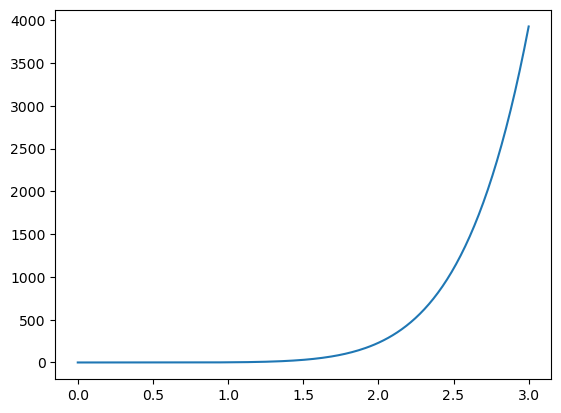

512⋅π
─────
  7  

In [29]:
def prob7():
    """Calculate the integral of f(x,y,z) = (x^2 + y^2 + z^2)^2 over the
    sphere of radius r. Lambdify the resulting expression and plot the integral
    value for r in [0,3]. Return the value of the integral when r = 2.

    Returns:
        (float): the integral of f over the sphere of radius 2.
    """
    x, y, z, rh, th, ph, r = sy.symbols("x, y, z, rh, th, ph, r")
    f = (x**2 + y**2 + z**2)**2
    h = sy.Matrix([rh*sy.sin(ph)*sy.cos(th), rh*sy.sin(ph)*sy.sin(th), rh*sy.cos(ph)])
    f = f.subs({x:h[0], y:h[1], z:h[2]})
    f = sy.simplify(f)
    J = h.jacobian([rh, th, ph])
    d = -sy.simplify(J.det())
    F = sy.integrate(f*d, (rh, 0, r), (th, 0, 2*sy.pi), (ph, 0, sy.pi))
    volume_f = sy.lambdify(r, F, "numpy")
    domain = np.linspace(0, 3, 200)
    plt.ion()
    plt.plot(domain, volume_f(domain))
    plt.show()

    return F.subs(r, 2)

value = prob7()
value

The integral works out to $\frac{4}{7}\pi r^7$, so $r = 2$ gives $\frac{512}{7}\pi$ and $r = 3$ gives the spec's check value $\frac{8748}{7}\pi$:

In [30]:
r = sy.symbols('r')
F = sy.Rational(4, 7)*sy.pi*r**7
value == F.subs(r, 2), F.subs(r, 3) == sy.Rational(8748, 7)*sy.pi

(True, True)

> **Achtung!** SymPy isn't perfect. It solves some integrals incorrectly, simplifies some expressions poorly, and is significantly slower than numerical computations. However, it is generally very useful for simplifying parts of an algorithm, getting exact answers, and handling tedious algebra quickly.

## Additional Material

### Pretty Printing

Complicated SymPy expressions can be hard to read. `sy.init_printing()` (called at the top of this notebook) makes them display more readably; in a Jupyter Notebook the rendering is done with $\LaTeX$. `sy.latex()` converts an expression into actual $\LaTeX$ code for use in other settings.

In [31]:
x, y = sy.symbols('x y')
expr = sy.Integral(sy.exp(-x**2)/(1 + y**2), (x, -sy.oo, sy.oo))
print(sy.latex(expr))
expr

\int\limits_{-\infty}^{\infty} \frac{e^{- x^{2}}}{y^{2} + 1}\, dx


∞           
⌠           
⎮      2    
⎮    -x     
⎮   ℯ       
⎮  ────── dx
⎮   2       
⎮  y  + 1   
⌡           
-∞          

### Limits

`sy.Limit()` expresses a limit (evaluated with `doit()`), and `sy.limit()` (lowercase) evaluates one directly; an optional fourth argument gives the direction. Use limits instead of `subs()` when the value to substitute is $\infty$ or a singularity. See http://docs.sympy.org/latest/tutorial/calculus.html for SymPy's documentation on calculus operations.

In [32]:
a, x = sy.symbols('a x')
print(sy.Limit(a**(1/x), x, sy.oo))                 # The limit of a^(1/x) as x approaches infinity.
print(sy.limit((1+x)**(1/x), x, 0), sy.limit(1/x, x, 0, '-'))   # The second approaches 0 from the left.
expr = x / 2**x
print(expr.subs(x, sy.oo), sy.limit(expr, x, sy.oo))

Limit(a**(1/x), x, oo, dir='-')
E -oo
nan 0


### Numerical Integration

Many integrals can't be solved analytically. As an alternative to `doit()`, the `as_sum()` method approximates an integral with a sum, given the number of terms and the rule (`"left"`, `"right"`, `"midpoint"`, or `"trapezoid"`). See http://docs.sympy.org/latest/modules/integrals/integrals.html for more on integration.

In [33]:
x = sy.symbols('x')
I = sy.Integral(sy.exp(x**2), (x,0,sy.pi))          # Try integrating e^(x^2) from 0 to pi.
print(I.doit())                                     # The result is not very helpful.
I.as_sum(10, 'left').evalf()                        # Instead, approximate the integral with a sum.

sqrt(pi)*erfi(pi)/2


1162.85031639195

### Differential Equations

SymPy solves both ordinary and partial differential equations (PDE functions: http://docs.sympy.org/dev/modules/solvers/pde.html). A first-order ODE has the general form $\frac{dx}{dt} = f(x(t), t)$. Represent the unknown function $x(t)$ with `sy.Function()`. Just as `sy.solve()` solves an expression for a variable, `sy.dsolve()` solves an ODE for a *function*; with multiple solutions it returns a list, and arbitrary constants appear as `C1`, `C2`, and so on. `sy.checkodesol()` checks that a function solves a differential equation. Since there are many kinds of ODEs, `sy.dsolve()` also accepts a hint for the solving strategy: see `sy.ode.allhints`, or use `sy.classify_ode()` to list the hints that may apply to an equation.

In [34]:
t = sy.symbols('t')
x = sy.Function('x')
ode = x(t).diff(t, t) - 2*x(t).diff(t) + x(t) - sy.sin(t)     # Solve x''(t) - 2x'(t) + x(t) = sin(t).
sol = sy.dsolve(ode, x(t))
print(sy.checkodesol(ode, sol))
sol                                                             # C1 and C2 are arbitrary constants.

(True, 0)


                    t   cos(t)
x(t) = (C₁ + C₂⋅t)⋅ℯ  + ──────
                          2   